## Classical McKay quivers

To get started, we construct McKay quivers for groups (the classical case).
The method used here is our general framework for once we move to more exotic representation theory: 
First we implement the Grothendieck group $\mathrm G_0(\mathbb CG)$,
in this case via its isomorphism to the character algebra.

In [1]:
def reorder_CT(CT):
    """For some reason GAP is not consistent in the order of character tables, this fixes that by making sure the trivial character is first and they are otherwise sorted by dimension"""
    n = CT.dimensions()[0]
    without_trivial = sorted(
        (
            row
            for row in CT
            if not all(i == 1 for i in row)
        ),
        key = lambda row: row[0]
    )
    return matrix([
        [1 for i in range(n)],
        *without_trivial
    ])

def dimensions_CT(CT):
    """List of prettier indices (d,i) where d is the dimension"""
    return [(r[0], i) for (i, r) in enumerate(CT)]

class FusionGroup(CombinatorialFreeModule):
    """
    The representation ring G₀(ℂG) for a permutation group $G$.
    """

    def __init__(self, G):
        self.G = G
        self.CT = reorder_CT(self.G.character_table())
        self.keys = dimensions_CT(self.CT)
        self.n = self.CT.dimensions()[0] # number of conjugacy classes
        CombinatorialFreeModule.__init__(self, ZZ, list(self.keys), category = AlgebrasWithBasis(ZZ), prefix = 'S')

    def one_basis(self):
        return (1,0)

    def product_on_basis(self, left, right):
        χ1 = self.CT[left[1]]
        χ2 = self.CT[right[1]]
        η = χ1.pairwise_product(χ2)
        return self.from_vector(vector(self._B(η, χ) for χ in self.CT))

    def _B(self, χ1,χ2):
        """Inner product on characters"""
        sizes = [k.cardinality() / self.G.order() for k in self.G.conjugacy_classes()]
        return sum(sizes[i] * χ1[i].conjugate() * χ2[i] for i in range(self.n))

    def _repr_(self):
         return "The representation ring K₀(ℂG) for G = %s" % (self.G)

Then this information can be used to construct a McKay quiver.

In [2]:
def mckay_quiver(G0, v):
    quiver = DiGraph(multiedges = True, loops = True)
    simples = G0.indices()
    for s in simples:
        quiver.add_vertex(s)
    for s_i in simples:
        w = G0.monomial(s_i) * v
        for s_j in simples:
            mult = w.monomial_coefficients(w).get(s_j, 0)
            for i in range(mult):
                quiver.add_edge(s_i, s_j)
    return quiver

The following example calculates Figure 1 in the paper:

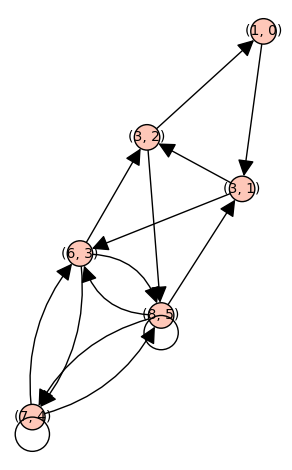

In [3]:
G_ℂ_PSL32 = FusionGroup(PSL(3,2))
Γ = mckay_quiver(G_ℂ_PSL32, G_ℂ_PSL32.monomial((3,1)))
Γ.plot()

A more standard example giving the Dynking quiver $\tilde{\mathrm D}_4$

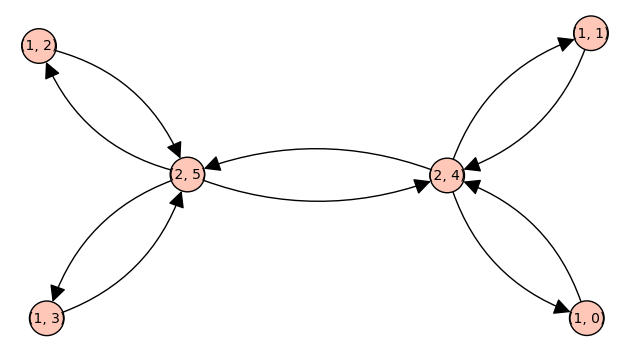

In [4]:
G_ℂ_DC3 = FusionGroup(DiCyclicGroup(3))
Γ = mckay_quiver(G_ℂ_DC3, G_ℂ_DC3.monomial((2,4)))
Γ.plot()

## Modular McKay quivers

The same strategy works for McKay quivers of non-semisimple group algebras (modular McKay quivers),
if we switch to Brauer characters.
Since SageMath does not natively support GAP's Brauer character tables,
we need to use GAP group objects rather than native ones.

In [5]:
SUB = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")

def Brauer_CT(G, p):
    """
    Brauer character table of a GAP group in mod p.
    """
    table = G.CharacterTable(p)
    rows = libgap.List(libgap.Irr(table), libgap.ValuesOfClassFunction)
    return Matrix(rows)

class ModularFusionGroup(CombinatorialFreeModule):
    """
    The representation ring G₀(ℂG) for a permutation group $G$.
    """

    def __init__(self, G, p):
        self.G = G
        self.p = p
        self.sub = str(self.p).translate(SUB)
        self.CT = reorder_CT(Brauer_CT(self.G, p))
        self.keys = dimensions_CT(self.CT)
        self.n = self.CT.dimensions()[0] # number of conjugacy classes
        CombinatorialFreeModule.__init__(self, ZZ, list(self.keys), category = AlgebrasWithBasis(ZZ), prefix = 'S')

    def one_basis(self):
        return (1,0)

    def product_on_basis(self, left, right):
        χ1 = self.CT[left[1]]
        χ2 = self.CT[right[1]]
        η = χ1.pairwise_product(χ2)
        return self.from_vector(self.CT.solve_left(η))

    def _repr_(self):
         return "The representation ring G₀(F%sG) for G = %s" % (self.sub , self.G)


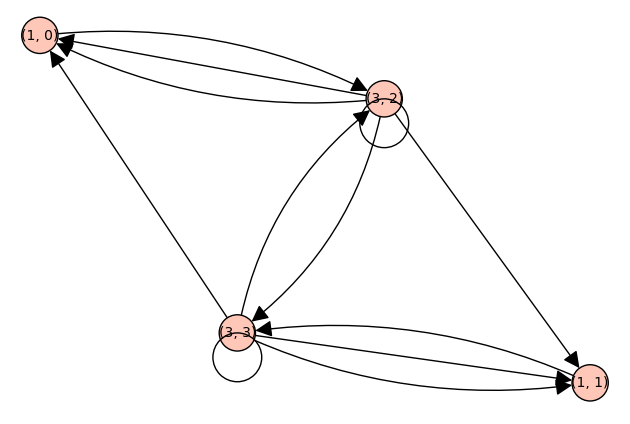

In [6]:
G_F3_Sym4 = ModularFusionGroup(gap.SymmetricGroup(4),3)
Γ = mckay_quiver(G_F3_Sym4, G_F3_Sym4.monomial((3,2)))
Γ.plot()

## Drinfel'd doubles of group algebras
Fusion rings for Drinfel'd doubles of group algebras are already implemented in SageMath.

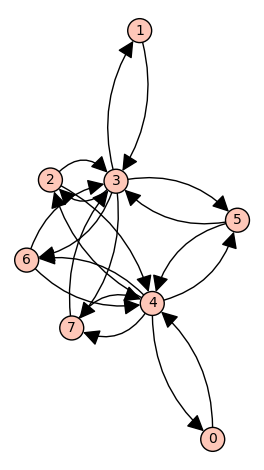

In [7]:
G_D_Sym3 = FusionDouble(SymmetricGroup(3))
Γ = mckay_quiver(G_D_Sym3, G_D_Sym3.monomial(4))
Γ.plot()

# Drinfel'd double of the Taft algebra

Using results from Chen et al. [one can shown](https://jaj.sh/Zen/Simple-modules-of-the-Drinfel'd-double-of-the-Taft-algebra#tensor-products) that $V(\ell, r) \otimes V(\ell', r')$ has equivalence class
$$
\sum_{i=0}^{\min\{\ell,\ell'\}-1} [V(\ell + \ell' -1  - 2i, r + r' + i)]
$$
if $\ell + \ell' < n$, and
$$
2\left( \sum_{i=0}^{\left\lfloor  \frac{\ell+\ell'-n-1}{2}  \right\rfloor} [V(\ell+\ell' -n-1-2i, r + r' + i)] + \sum_{i= \left\lfloor  \frac{\ell+\ell'-n}{2} \right\rfloor}^{\ell + \ell' - n - 1} [V(\ell+\ell'-1-2i, r+r'+i)]  \right)
\\
+ \sum_{i=\ell+\ell'-n}^{\min \{ \ell,\ell' \}-1} [V(\ell+\ell'-1-2i,r+r'+i)]
$$
otherwise.
We use this to implement $\mathrm G_0(\mathcal D_n(\zeta_n))$.

In [8]:
import itertools

SUB = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")

class FusionDoubleTaft(CombinatorialFreeModule):
    """
    The representation ring G₀(𝒟ₙ(ζₙ)) of the Drinfel'd double 𝒟ₙ(ζₙ) of the Taft algebra
    """

    def __init__(self, n):
        self.n = n
        self.sub = str(self.n).translate(SUB)
        self.ℤₙ = Integers(n)
        self.keys = list(itertools.product(range(1,n+1), self.ℤₙ))
        CombinatorialFreeModule.__init__(self, ZZ, self.keys, category = AlgebrasWithBasis(ZZ), prefix = 'V')

    def one_basis(self):
        return (1, self.ℤₙ(0))

    def V(self, l, r):
        return self.monomial((l, self.ℤₙ(r)))
    
    def product_on_basis(self, left, right):
        n = self.n
        (l1, r1) = left
        (l2, r2) = right

        if l1 + l2 < n:
            return sum(
                self.V(l1 + l2 - 1 - 2*i, self.ℤₙ(r1 + r2 + i))
                for i in range(min(l1, l2))
            )
        else: 
            # The end of each summation plus one
            cut1 = floor((l1 + l2 - n)/2)
            cut2 = l1 + l2 - n
            cut3 = min(l1, l2)
    
            sum1 = sum(
                self.V(l1 + l2 - n - 1 - 2*i, self.ℤₙ(r1 + r2 + i))
                for i in range(cut1)
            )
            sum2 = sum(
                self.V(l1 + l2 - 1 - 2*i, self.ℤₙ(r1 + r2 + i))
                for i in range(cut1, cut2)
            )
            sum3 = sum(
                self.V(l1 + l2 - 1 - 2*i, self.ℤₙ(r1 + r2 + i))
                for i in range(cut2, cut3)
            )

            return 2*(sum1 + sum2) + sum3

    def _repr_(self):
        return "The representation ring G₀(𝒟%s(ζ%s))" % (self.sub, self.sub)

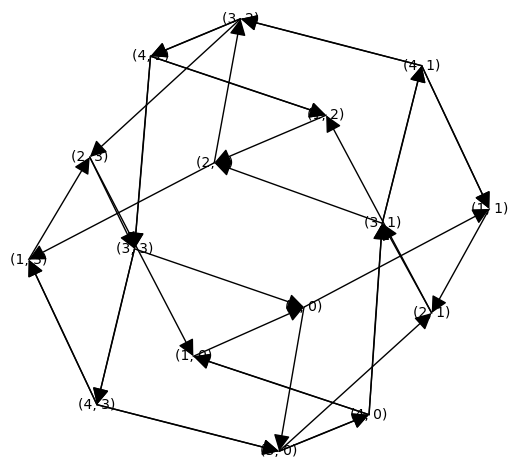

In [9]:
G_D4 = FusionDoubleTaft(4)
Γ = mckay_quiver(G_D4, G_D4.V(2, 0))
Γ.plot(layout="graphviz", prog="neato")

We note that the automorphism group of the above quiver is given by the group of 1-dimensional $\mathcal{D}_n(\zeta_n)$-modules.

In [10]:
[g.order() for g in Γ.automorphism_group()]

[1, 4, 2, 4]

In [11]:
[G_D4.V(1,1)^i for i in range(4)]

[V[(1, 0)], V[(1, 1)], V[(1, 2)], V[(1, 3)]]